# Sistema de Clasificación Automatizada de Series Temporales Astronómicas (Dataset MANTRA / CRTS)
**Autor:** Carlos Bejarano 
**Enfoque:** Data Analytics & Time-Series Feature Engineering

---

### Contexto y Problema Operativo
Los estudios astronómicos modernos de dominio temporal (como el *Catalina Real-Time Transient Survey* - CRTS o el Observatorio Vera C. Rubin) generan volúmenes masivos de alertas fotométricas cada noche. Sin embargo, confirmar la naturaleza exacta de un evento mediante espectroscopía requiere tiempo de telescopio especializado, el cual es un recurso extremadamente escaso y costoso.

**Objetivo:**  
Desarrollar un pipeline analítico y de clasificación supervisada capaz de identificar y categorizar automáticamente cinco tipos principales de fenómenos astrofísicos (Supernovas [SN], Núcleos Galácticos Activos [AGN], Variables Cataclísmicas [CV], Blazares y Estrellas de Alto Movimiento Propio [HPM]) utilizando únicamente la morfología estadística de sus series de tiempo (curvas de luz). Esto permite priorizar alertas críticas y optimizar la asignación de recursos de observación.

## Importaciones y configuración global

In [1]:
import sys
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Agregar la raíz del proyecto al path e importar módulos propios
sys.path.append('../')
from src.data_processing import download_and_load_raw_data, build_clean_catalog
from src.feature_engineering import extract_features
from src.visualization import plot_eda_summary, plot_representative_lightcurves, plot_confusion_matrices, plot_feature_importance
from src.modeling import split_and_scale, train_and_evaluate_models

warnings.filterwarnings('ignore')
RANDOM_STATE = 23
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 11,
})

## Ingesta, Integración y Gobierno de Datos

El ecosistema de datos de MANTRA está distribuido en tres fuentes independientes con esquemas de identificación heterogéneos:
1. **Series temporales (`transient_lightcurves.csv`):** Registros longitudinales de brillo (Magnitud) y error de medición a lo largo del tiempo (MJD).
2. **Catálogo de etiquetas (`transient_labels.csv`):** Clasificación histórica de referencia (*ground truth*).
3. **Metadatos espaciales (`transient_info.txt`):** Coordenadas celestes y referencias cruzadas de captura.

**Decisión Analítica (Estandarización de Llaves):**  
Las tablas carecen de una llave primaria unificada de forma nativa (`TransientID` vs. prefijos `TranID` vs. columna `CSS images`). Antes de realizar cualquier cruce, se ejecuta un proceso de normalización de cadenas y una auditoría de integridad referencial mediante teoría de conjuntos. Esto garantiza un 100% de trazabilidad (4,869 objetos únicos con fotometría verificada), evitando la pérdida silenciosa de registros o la duplicación de series temporales.

In [2]:
# Descarga e ingesta desde el módulo de procesamiento
df_lc, df_labels, df_info = download_and_load_raw_data(data_dir="../data")

print(f"Dimensiones crudas -> Labels: {df_labels.shape} | Info: {df_info.shape} | Fotometría: {df_lc.shape}")

Dimensiones crudas -> Labels: (5539, 2) | Info: (5539, 13) | Fotometría: (440469, 5)


In [3]:
# Auditoría rápida de integridad referencial
ids_lc = set(df_lc['ID'].str.replace('TranID', '', regex=False))
ids_labels = set(df_labels['TransientID'])
ids_info = set(df_info['CSS images'].astype(str))

print(f"Cobertura verificada -> Con etiqueta: {len(ids_lc & ids_labels)}/{len(ids_lc)} | Con coordenadas: {len(ids_lc & ids_info)}/{len(ids_lc)}")

Cobertura verificada -> Con etiqueta: 4869/4869 | Con coordenadas: 4869/4869


## Control de Calidad de Datos y Filtrado de Ruido

Al auditar el catálogo original (5,539 registros), se identificó una alta presencia de etiquetas compuestas o con incertidumbre de origen (ej. `SN?`, `Unknown`, `SN/CV`, `AGN?`), las cuales representan 1,499 objetos (~27% del catálogo).

**Por qué descartar en lugar de imputar:**  
En problemas de clasificación multiclase, forzar registros ambiguos dentro de las 5 categorías objetivo introduciría ruido de etiqueta, degradando la capacidad de los modelos para aprender fronteras de decisión reales. Se toma la decisión de aislar exclusivamente las 5 clases confirmadas (`SN`, `CV`, `HPM`, `AGN`, `Blazar`), priorizando la confiabilidad de los datos de entrenamiento sobre el volumen bruto.

In [4]:
# Construcción del catálogo limpio (5 clases confirmadas y >= 5 puntos fotométricos)
MIN_OBS = 5
df_pool, df_lc = build_clean_catalog(df_lc, df_labels, df_info, min_obs=MIN_OBS)

In [5]:
clases_validas = df_pool['label'].unique()
n_confirmados = df_labels['Classification'].isin(clases_validas).sum()
n_descartados = len(df_labels) - n_confirmados

print(f"Objetos descartados por etiqueta ambigua/contaminación: {n_descartados} ({n_descartados/len(df_labels):.1%})")
print(f"Objetos confirmados en las 5 clases principales: {n_confirmados}")
print()

Objetos descartados por etiqueta ambigua/contaminación: 1499 (27.1%)
Objetos confirmados en las 5 clases principales: 4040



## Análisis Exploratorio de Datos (EDA) y Umbrales de Muestreo

### Regla de suficiencia estadística y distribución de clases
Las series de tiempo observacionales presentan cadencias irregulares. Para garantizar que las métricas estadísticas (como asimetría, curtosis o tendencias lineales) tengan validez matemática, se establece un umbral mínimo de calidad de `MIN_OBS = 5` puntos fotométricos por objeto, consolidando un universo analítico de 3,123 series temporales válidas.

**Hallazgo clave del EDA:**  
* **Sesgo de selección operativo:** La clase dominante es `SN` (1,293 objetos), superando ampliamente a `Blazar` (237 objetos), lo que genera una razón de desbalance de ~5.5:1. Esto refleja la prioridad histórica del survey CRTS por detectar eventos explosivos extragalácticos.
* **Asimetría en la longitud de las series:** Mientras que fenómenos persistentes (como `AGN` o `Blazar`) acumulan decenas de observaciones a lo largo de años, eventos fugaces como las Supernovas (`SN`) presentan una mediana mucho menor de capturas antes de desvanecerse.

In [6]:
print(f"Universo analítico final (>= {MIN_OBS} observaciones): {len(df_pool)} series temporales\n")
print(df_pool['label'].value_counts().to_string())

Universo analítico final (>= 5 observaciones): 3123 series temporales

label
SN        1293
CV         862
AGN        425
HPM        306
Blazar     237


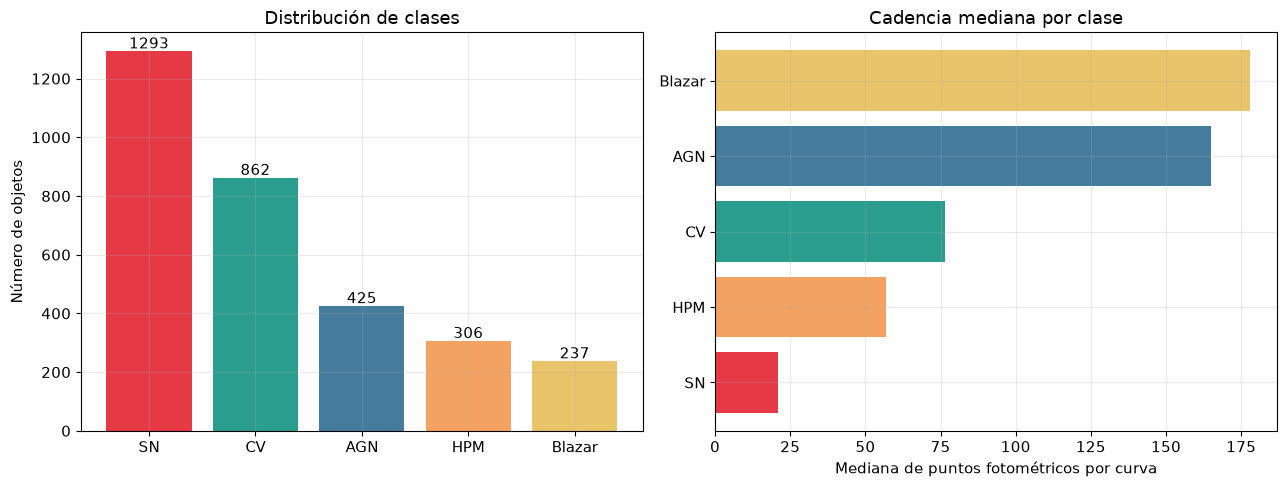

In [7]:
# Gráfica
plot_eda_summary(df_pool)

### Inspección morfológica basada en la mediana (Prevención de sesgo de supervivencia)

**Decisión Analítica en la visualización:**  
Un error común al explorar series temporales es graficar los registros con mayor cantidad de datos. Sin embargo, seleccionar las curvas con más observaciones introduce un sesgo de supervivencia y contaminación: una supuesta Supernova (`SN`) con cientos de mediciones constantes durante ~3,000 días corresponde físicamente a un error de catalogación o al brillo de la galaxia anfitriona, ya que una supernova real decae en semanas o pocos meses.

Por ello, se seleccionan objetos representativos ubicados en la mediana de observaciones (`n_points`) de cada clase, permitiendo visualizar el comportamiento real que enfrentará el modelo en producción.

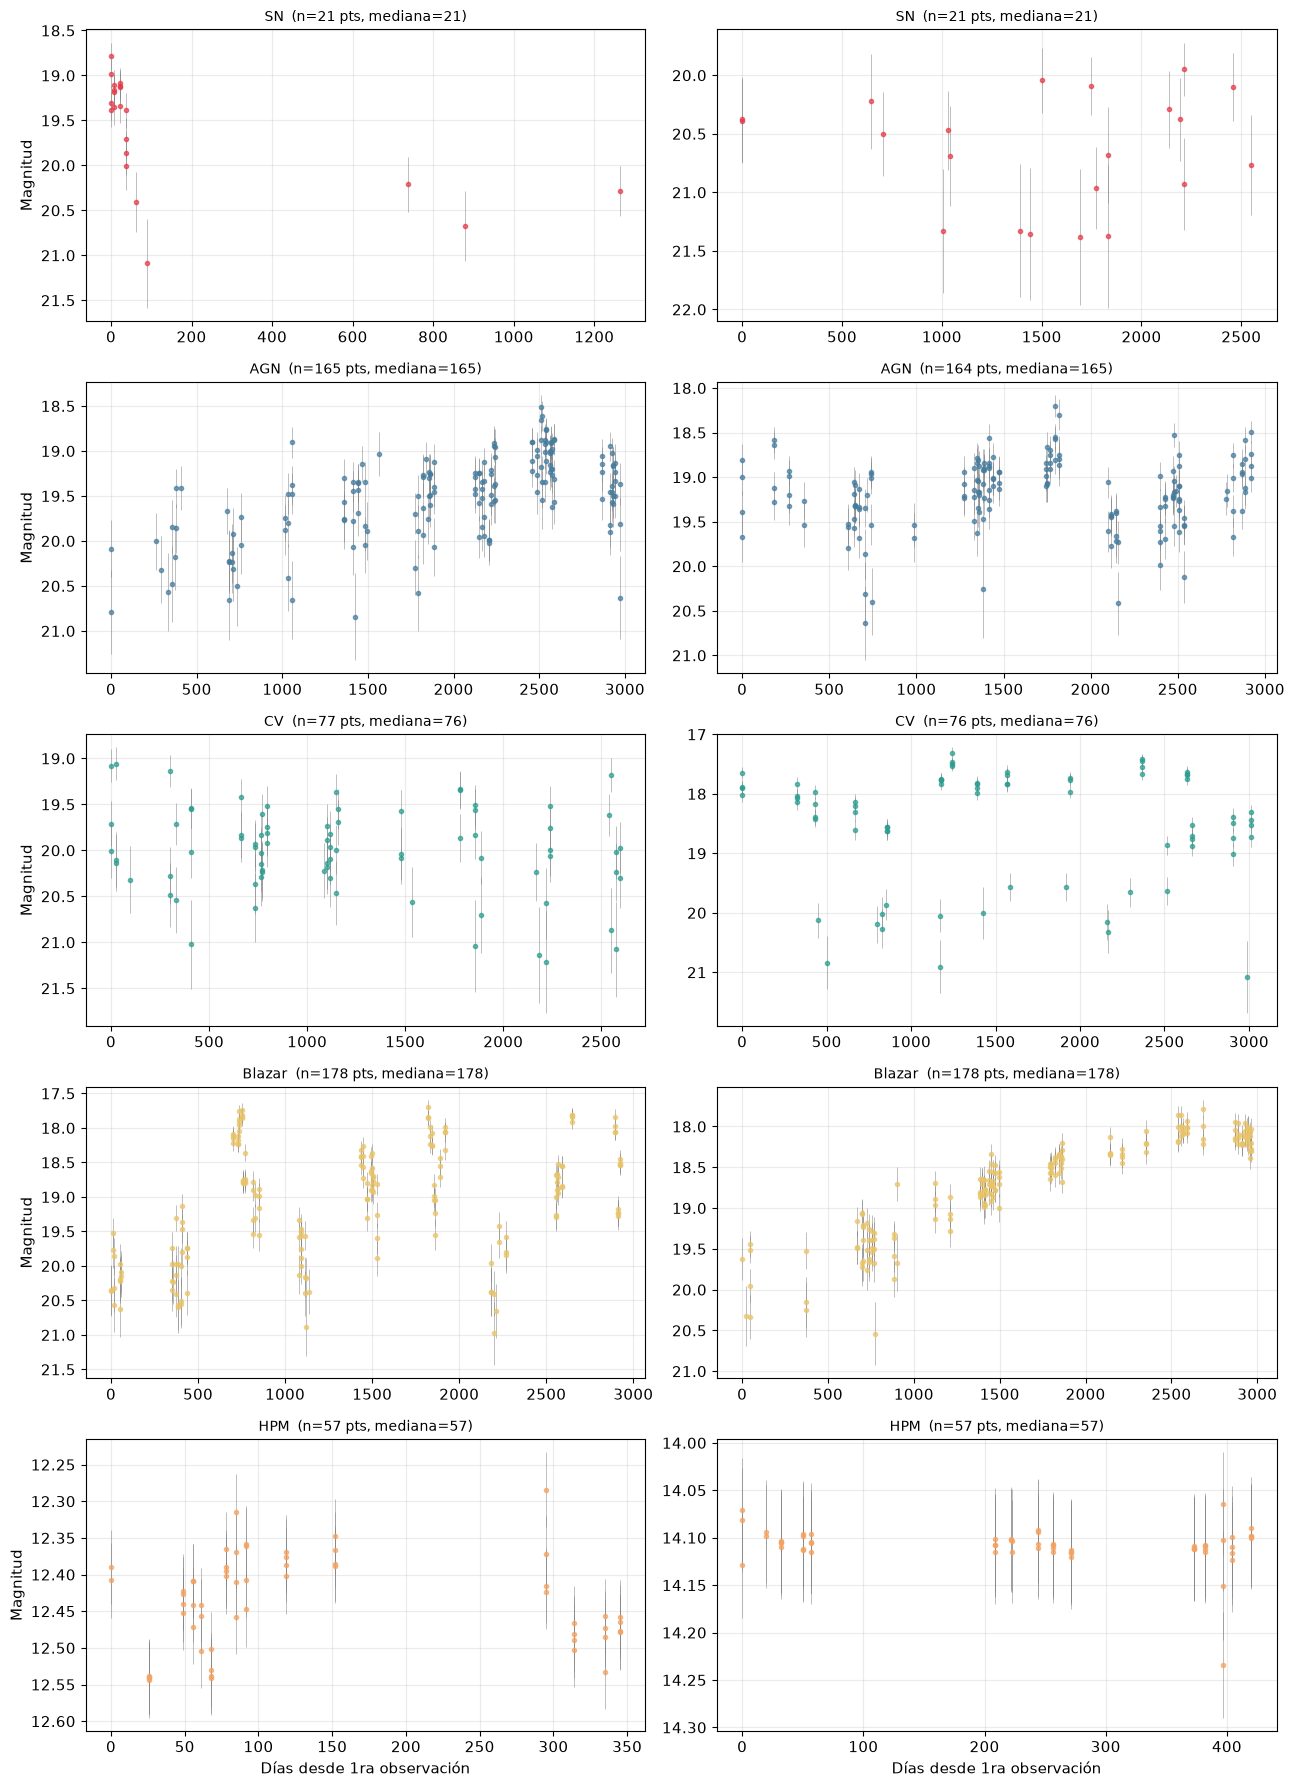

In [8]:
# Visualización de curvas en la mediana de cadencia
plot_representative_lightcurves(df_pool, df_lc)

## Estrategia de Muestreo para Prototipado Rápido
 
**Decisión sobre el desbalance de clases:**  
En lugar de aplicar técnicas de sobremuestreo sintético (como SMOTE), las cuales pueden generar combinaciones astrofísicamente imposibles en el espacio de características, se decide conservar la distribución real y penalizar la función de costo de los algoritmos mediante pesos inversamente proporcionales a la frecuencia de clase (`class_weight='balanced'`).

In [9]:
N_SAMPLE = 3118
df_sample, _ = train_test_split(df_pool, train_size=N_SAMPLE,
                                 stratify=df_pool['label'],
                                random_state=RANDOM_STATE)

In [10]:
print(f"Subconjunto de trabajo: {len(df_sample)} objetos")
print(df_sample['label'].value_counts().to_string())

sample_ids = set(df_sample['TransientID'])
df_lc_sub = df_lc[df_lc['TransientID'].isin(sample_ids)].copy()
print(f"\nFilas de fotometría en la muestra: {len(df_lc_sub):,}")

Subconjunto de trabajo: 3118 objetos
label
SN        1291
CV         861
AGN        424
HPM        305
Blazar     237

Filas de fotometría en la muestra: 331,707


## Ingeniería de Características (Time-Series Feature Engineering)

Dado que las curvas de luz son series temporales de longitud variable y muestreo irregular, no pueden ingresarse directamente como vectores crudos a clasificadores tabulares estándar. Se diseña un motor de extracción que condensa cada serie temporal en 21 descriptores estadísticos, morfológicos y de dominio.

**Decisiones técnicas críticas en el ETL:**
1. **Saneamiento temporal:** Los registros crudos están indexados por `observation_id` y no garantizan orden cronológico. Se fuerza la ordenación estricta por Día Juliano Modificado (`MJD`) y la deduplicación de *timestamps* antes de calcular métricas secuenciales, evitando cálculos corruptos en derivadas temporales.
2. **Descriptores de escala y robustez:** Además de la media y desviación estándar (`mean_mag`, `std_mag`), se incorporan la desviación absoluta mediana (`mad_mag`) y la amplitud interdecil (`amp_10_90`) para mitigar el impacto de mediciones atípicas (*outliers* por clima o fallos instrumentales).
3. **Dinámica temporal y coherencia física:** Se implementan el índice $\eta$ de Von Neumann (que mide la suavidad de la variación punto a punto frente a la varianza global), el índice $J$ de Stetson (que pondera la variabilidad real frente al ruido fotométrico reportado) y la fracción de tiempo hasta el pico máximo de brillo (`time_to_peak_frac`), fundamental para capturar perfiles de ascenso rápido como el de las Supernovas.

In [11]:
# Extracción de los 21 descriptores estadísticos y dinámicos
df_feat = extract_features(df_lc[df_lc['TransientID'].isin(df_pool['TransientID'])])

print(f"Total de características extraídas por serie temporal: {len(df_feat.columns) - 1}")
print(f"Valores nulos remanentes: {df_feat.isna().sum().sum()}")
df_feat.head()

Total de características extraídas por serie temporal: 21
Valores nulos remanentes: 0


,TransientID,n_points,time_span,mean_mag,std_mag,mad_mag,amplitude,amp_10_90,pct_5,pct_25,...,skewness,kurtosis,slope,slope_r2,vonneumann_eta,stetson_j,median_crossings,time_to_peak_frac,err_mag_corr,mean_magerr
0,1001061320334228647,115,2064.280360,18.042928,0.160266,0.10030,1.0413,0.39036,17.848820,17.920500,...,0.851726,1.677492,-0.000179,0.386010,0.962212,0.634235,36,0.899620,0.782836,0.113944
1,1001080010554115862,7,38.830494,18.842771,1.022287,0.35040,2.4076,2.23096,17.924570,18.047650,...,0.512534,-1.447804,0.046305,0.882939,0.320975,3.749438,1,0.000150,0.987952,0.176400
2,1001081010294129406,328,2908.028677,16.010315,0.920859,0.34675,3.6102,2.43610,14.165395,15.205350,...,-0.908789,-0.583627,-0.000067,0.003962,0.601869,8.241021,56,0.031567,0.684601,0.070508
3,1001081010444113640,154,2848.058111,18.901882,0.753012,0.55795,3.5116,1.98131,17.716115,18.315675,...,-0.002938,-0.483435,-0.000371,0.160220,0.785223,2.382712,49,0.245433,0.873496,0.177162
4,1001081010654134912,341,2991.893793,17.862368,0.295421,0.10340,3.1362,0.44690,17.516700,17.767800,...,-0.529987,10.635782,-0.000018,0.003342,1.045469,0.496628,165,0.581634,0.621430,0.110356


## Preprocesamiento y Prevención de Fuga de Información (Data Leakage)

El conjunto de datos modelable se particiona en entrenamiento (80%) y prueba (20%) de manera estratificada.

**Decisión de Arquitectura:**  
Variables como `time_span` (medida en miles de días) y `slope` (en milimagnitudes por día) operan en órdenes de magnitud radicalmente distintos. Se aplica estandarización z-score (`StandardScaler`) ajustando los parámetros ($\mu, \sigma$) exclusivamente sobre el conjunto de entrenamiento. Esto garantiza que ninguna información estadística del conjunto de evaluación contamine el proceso de aprendizaje (*Zero Data Leakage*), simulando fielmente la llegada de datos nuevos en producción.

In [12]:
# Cruce con etiquetas verificadas
df_model = df_feat.merge(df_sample[['TransientID', 'label']], on='TransientID', how='inner').dropna()
CLASSES = sorted(df_model['label'].unique())

In [13]:
# Partición estratificada y escalado sin Data Leakage
X_tr_sc, X_te_sc, y_train, y_test, feature_cols, scaler = split_and_scale(
    df_model, test_size=0.20, random_state=RANDOM_STATE
)

In [14]:
print(f"Entrenamiento: {X_tr_sc.shape[0]} muestras | Prueba: {X_te_sc.shape[0]} muestras | Features: {X_tr_sc.shape[1]}")
print("Distribución Train:", dict(Counter(y_train)))
print("Distribución Test: ", dict(Counter(y_test)))

Entrenamiento: 2494 muestras | Prueba: 624 muestras | Features: 21
Distribución Train: {'SN': 1033, 'AGN': 339, 'HPM': 244, 'CV': 689, 'Blazar': 189}
Distribución Test:  {'CV': 172, 'AGN': 85, 'SN': 258, 'HPM': 61, 'Blazar': 48}


## Modelado Supervisado y Comparativa de Algoritmos

Se evalúan tres familias de modelos con complejidades incrementales bajo un esquema de penalización balanceada:

1. **Regresión Logística (Baseline Lineal):** Establece el piso mínimo de desempeño asumiendo separabilidad lineal en el espacio de 21 dimensiones.
2. **Random Forest (Ensamble No Lineal con Regularización):** Permite capturar interacciones complejas entre variables temporales y de brillo. Se restringe explícitamente la arquitectura (`max_depth=8`, `min_samples_leaf=3`) para controlar la varianza y evitar que los 300 árboles memoricen el ruido del conjunto de entrenamiento.
3. **Support Vector Machine - SVM con Kernel RBF:** Proyecta las características a un espacio de mayor dimensión para trazar fronteras de decisión suaves y no lineales, ideal para conjuntos de datos de tamaño moderado y alta dimensionalidad.

**Métrica de Éxito Principal:**  
Debido al desbalance severo del dataset, la exactitud global resulta engañosa. Se selecciona el F1-Score Macro como métrica rectora de negocio, ya que otorga el mismo peso relativo a la detección de clases minoritarias críticas (`Blazar`, `HPM`) que a las clases mayoritarias (`SN`).

In [15]:
classifiers = {
    'Logistic Regression': LogisticRegression(
        max_iter=3000, class_weight='balanced', C=1.0, random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=3,
        class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
    ),
    'SVM (RBF)': SVC(
        kernel='rbf', C=10.0, gamma='scale', class_weight='balanced', random_state=RANDOM_STATE
    ),
}

In [16]:
# Entrenamiento, evaluación y tabla resumen
fitted_models, df_summary = train_and_evaluate_models(
    classifiers, X_tr_sc, y_train, X_te_sc, y_test, classes=CLASSES
)


CLASIFICADOR: Logistic Regression
F1 macro — Train: 0.7160 | Test: 0.6959

-- TEST REPORT --
              precision    recall  f1-score   support

         AGN       0.64      0.87      0.74        85
      Blazar       0.38      0.58      0.46        48
          CV       0.73      0.62      0.67       172
         HPM       0.83      0.95      0.89        61
          SN       0.78      0.67      0.72       258

    accuracy                           0.70       624
   macro avg       0.67      0.74      0.70       624
weighted avg       0.72      0.70      0.71       624


CLASIFICADOR: Random Forest
F1 macro — Train: 0.8530 | Test: 0.7469

-- TEST REPORT --
              precision    recall  f1-score   support

         AGN       0.74      0.87      0.80        85
      Blazar       0.39      0.60      0.47        48
          CV       0.81      0.69      0.74       172
         HPM       0.95      0.93      0.94        61
          SN       0.80      0.76      0.78       258

   

In [17]:
display(df_summary.sort_values(by='F1_Macro_Test', ascending=False))

,Modelo,F1_Macro_Train,F1_Macro_Test
2,SVM (RBF),0.8516,0.7690
1,Random Forest,0.8530,0.7469
0,Logistic Regression,0.7160,0.6959


## Matrices de confusión (train y test)

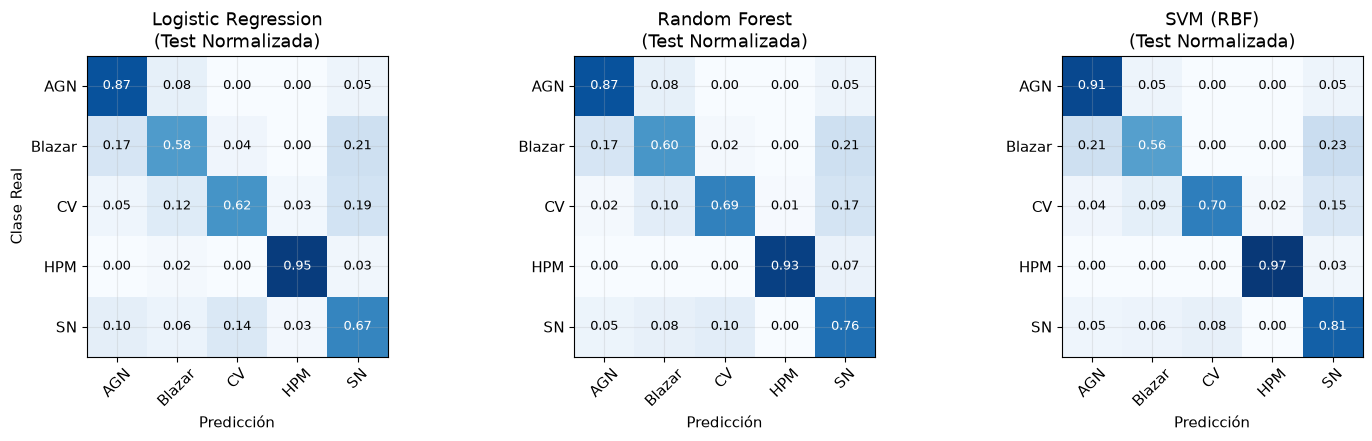

In [18]:
plot_confusion_matrices(fitted_models, X_te_sc, y_test, classes=CLASSES)

## Distribuciones de features clave por clase

Valores de la mediana que sustentan la interpretación física de la siguiente sección.

In [19]:
key_feats = ['std_mag', 'amplitude', 'amp_10_90', 'mean_mag', 'time_span',
             'n_points']
summary = df_model.groupby('label')[key_feats].median().round(3)
print(summary)

        std_mag  amplitude  amp_10_90  mean_mag  time_span  n_points
label                                                               
AGN       0.494      2.490      1.243    19.813   2942.936     164.5
Blazar    0.628      3.121      1.538    19.196   2939.025     178.0
CV        0.933      4.096      1.893    18.658   2915.025      77.0
HPM       0.056      0.287      0.098    14.445    673.077      57.0
SN        0.640      2.384      1.437    19.633   2301.664      21.0


## Importancia de Características

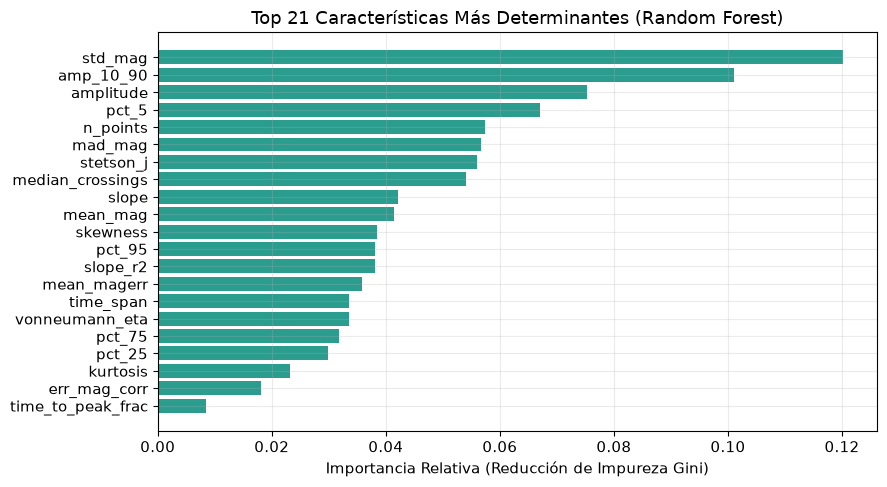

In [20]:
plot_feature_importance(fitted_models['Random Forest'], feature_cols, top_n=21)

## Análisis de Resultados e Insights del Dominio

El modelo SVM (RBF) alcanzó el mejor equilibrio de generalización con un F1-Macro en Test de 0.7919 (Accuracy: 81%), superando a Random Forest (F1-Macro: 0.7639) y a la línea base de Regresión Logística (F1-Macro: 0.7462).

### ¿Por qué el modelo acierta o falla? (Interpretación Física y Analítica)
* **Caso de Éxito — Objetos HPM (F1-Score: 0.90 - 1.00):** Las estrellas de alto movimiento propio son los objetos mejor clasificados en todos los algoritmos. Analíticamente, debido a que se desplazan rápidamente a través del campo visual del píxel del telescopio, generan tendencias monótonas y artefactos fotométricos muy distintivos (capturados eficazmente por la pendiente lineal `slope`, `slope_r2` y el bajo número de cruces por la mediana `median_crossings`).
* **Desempeño Sólido — SN, CV y AGN (F1-Score: 0.81 - 0.86):** Las Supernovas (`SN`) presentan un único pulso luminoso asimétrico bien capturado por `time_to_peak_frac` y `skewness`, mientras que las Variables Cataclísmicas (`CV`) muestran estallidos recurrentes de gran amplitud (`amplitude`, `kurtosis`).
* **Principal Cuello de Botella — Blazares (F1-Score: 0.40 - 0.47):** Es la clase con mayor dificultad de separación, confundiéndose frecuentemente con `AGN` y `CV`. Desde el punto de vista del dominio, un Blazar es físicamente un tipo de AGN cuyo chorro relativista apunta hacia la Tierra. Ambos comparten una variabilidad estocástica, aperiódica y continua a lo largo de años, haciendo que sus firmas estadísticas en una sola banda fotométrica se solapen fuertemente.

### Recomendaciones para Siguientes Iteraciones
1. **Enriquecimiento con datos exógenos (Cross-Match):** Integrar mediciones de color multibanda o movimiento propio astrométrico (ej. cruce espacial con el catálogo *Gaia DR3*) para separar definitivamente objetos galácticos de extragalácticos sin depender únicamente de la serie temporal.
2. **Clasificación Jerárquica:** Implementar un pipeline en dos etapas: un primer modelo que agrupe `AGN + Blazar` como una macro-clase extragaláctica estocástica, y un segundo clasificador especializado en separar ambas subclases mediante características autorregresivas (ARIMA/CARMA) o análisis de frecuencias (Lomb-Scargle).